# Several Outputs

> **Overview.** The growing LTUs of 05 with 10 outputs instead of one, each reading 4 of 8 target LTUs: do more outputs
> make the features easier to find?

The step after `05_fast_feature_search.ipynb`, toward the deep sparse target network, whose 100 outputs share its
hidden units. With one output, each LTU's error mixes all 8 target LTUs equally. Here each LTU's shadow weight is on one
random output, which reads only 4 target LTUs, and its starting inputs are sampled by that output's linear weights.
**Hypothesis:** more outputs give more learning signal, so the LTUs find the features sooner than in
`05_fast_feature_search.ipynb`, where they reached RMSE 0.2 about 280k steps after being added.

**Problem.** $N = 1000$ standard normal inputs. 8 target LTUs, each reading 10 inputs drawn at random, with random
$\pm 1$ weights and threshold 0, giving $\pm 1$. 10 outputs, each reading 4 target LTUs drawn at random with random
weights $\pm \frac{1}{2}$, plus $N(0, 0.1^2)$ noise. The best possible RMSE is 0.1 (dotted line), and the best linear
learner's about 0.61 (dashed line). Each seed has its own target network.

**Learner.** As in `05_fast_feature_search.ipynb`: the linear learner (every output reads every input), a bias, and 32
hidden LTUs (sigmoid derivative backward), standardized online; network Autostep (`squared_inputs`, initial step-size
$10^{-4}$, meta step-size 0.02, $\tau = 10^4$). Every LTU feeds every output. Each LTU has a shadow weight, +1 and -1
alternately, on one output drawn at random: in the backward pass it stands in for the LTU's real weight to that output
while the real one is smaller than 1 in magnitude, and the LTU's other output weights are used as they are. The linear
learner learns alone for the first 100k steps; then the LTUs are added, each reading 1 to 20 inputs (its fan-in
uniform) drawn without replacement with probability proportional to the square of its shadow output's linear weight on
each, and everything learns for 500k more steps. Fast learning, growth and search as in
`05_fast_feature_search.ipynb`, the signs coming from the shadow output's linear weights, and search replacing the 4
LTUs with the smallest sum of output weight magnitudes.

**Runs.** 5 seeds per configuration; the same seed gives every run the same target network and samples. *Growth with
fast search every 10k steps* (proposed). *Growth without search* (proposed). *Fully connected* (baseline): the linear
learner and 32 LTUs reading every input, all learning from the first step, the LTUs' input weights LeCun uniform over the
1,000 inputs, with no fast learning, growth or search. *LTUs reading one target LTU's inputs* (reference): each pair of
LTUs reads one target LTU's 10 inputs, with its shadow weights on an output that reads that target LTU, fast learning,
and no search or growth. *Linear learner* (baseline): no LTUs. Curves are the mean over seeds of the RMSE over the 10
outputs, averaged over windows of 1k steps; final performance is the RMSE over the last 10% of steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 10
OUTPUT_FAN_IN = 4                    # target LTUs each output reads, drawn at random
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs
MAX_FAN_IN = 20                      # LTUs with sampled inputs read 1 to MAX_FAN_IN of them
REPLACED = 4                         # LTUs replaced at each search step, those with the smallest sum of |output weights|
FAST_STEP_SIZE = 3e-2                # initial step-size of the input weights of LTUs that learn fast
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 500_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps


## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read, 0 elsewhere
    out: jax.Array              # (N_OUTPUTS, N_TARGETS): the outputs' weights, +-1/2 on the target LTUs they read


def make_target(key):
    # A target network: each target LTU reads N_SOURCES inputs and each output OUTPUT_FAN_IN target LTUs, all drawn at
    # random, with random +-1 weights (the outputs' scaled to unit variance).
    read_key, w_key, out_key, out_w_key = jax.random.split(key, 4)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = jax.random.rademacher(w_key, (N_TARGETS, N_INPUTS), dtype=float) * pick(read_key, (N_TARGETS, N_INPUTS), N_SOURCES)
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_TARGETS), dtype=float)
           * pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN) / np.sqrt(OUTPUT_FAN_IN))
    return Target(w, out)


def sample(target, key):
    # One input and its noisy targets.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, target.out @ jnp.where(target.w @ x > 0, 1.0, -1.0) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the outputs' weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the outputs' connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, slots): each hidden unit's shadow weight, +-1 on one output, 0 elsewhere
    candidates: jax.Array       # (slots, N_INPUTS): sum of dL/dz * x_i since each unit's last new connection


def active(net):
    # Which slots hold a hidden unit.
    return jnp.any(net.shadow != 0, 0)


def shadow_linear(net):
    # (slots, N_INPUTS): each hidden unit's shadow weight times its shadow output's linear weights.
    return net.shadow.T @ net.w['output'][:, :N_INPUTS]


def init_net(key, target, units, slots, sampled, dense=False):
    # `units` hidden units in `slots` slots, the rest left empty, each pair reading one target LTU's inputs in turn
    # (every input if dense) and the bias, with LeCun uniform input weights over their fan-in; their shadow weights +1
    # and -1 alternately, each on an output drawn at random among those that read its target LTU (among all outputs if
    # sampled or dense); every other weight at 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(slots) // 2 % N_TARGETS
    reads = jnp.append((target.w[assigned] != 0) | dense, jnp.ones((slots, 1), bool), axis=1)
    fan_in = N_INPUTS if dense else N_SOURCES
    readers = (target.out[:, assigned] != 0) | sampled | dense
    shadow_out = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    sign = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == shadow_out) * sign
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + slots + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': (jax.random.uniform(w_key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((slots, N_INPUTS)))


def rewire(net, key, replaced):
    # The `replaced` hidden units (a mask over slots) each read 1 to MAX_FAN_IN inputs (uniform) and the bias, the
    # inputs drawn without replacement with probability proportional to the square of their shadow output's linear
    # weight on them (Gumbel top-k), with fresh LeCun uniform input weights over their fan-in, output weights at 0, and
    # fresh statistics, Autostep state and gradient sums. Each keeps its shadow weight.
    slots = len(net.reads)
    fan_key, draw_key, w_key = jax.random.split(key, 3)
    fan_in = jax.random.randint(fan_key, (slots, 1), 1, MAX_FAN_IN + 1)
    scores = jnp.log(shadow_linear(net) ** 2) + jax.random.gumbel(draw_key, (slots, N_INPUTS))
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((slots, 1), bool), axis=1)
    hidden = jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / fan_in) * reads
    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    opt = net.opt._replace(beta=reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros)),
                           h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=jnp.where(replaced[:, None], reads, net.reads), opt=opt, stats=stats,
                        candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def speed_up(net, replaced):
    # The `replaced` hidden units' input weights keep their magnitudes but take the signs of their shadow weight times
    # their shadow output's linear weights on those inputs, and their step-sizes start at FAST_STEP_SIZE.
    inputs = net.reads.at[:, -1].set(False) & replaced[:, None]
    signs = jnp.sign(jnp.pad(shadow_linear(net), ((0, 0), (0, 1))))
    hidden = jnp.where(inputs, jnp.abs(net.w['hidden']) * signs, net.w['hidden'])
    beta = jnp.where(inputs, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their
    # root mean square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each shadow weight
    # standing in for its hidden unit's weight to that output in the backward pass while the real one is smaller in
    # magnitude, the hidden units' other output weights used as they are. Returns the new network and the squared error
    # on this sample averaged over the outputs, before learning from it, and adds dL/dz * x_i to each hidden unit's
    # gradient sums. `probe` is zero; its gradients are the error arriving at each hidden unit and dL/dz.
    units = len(net.reads)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:N_INPUTS + units]
        back = jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w) * net.mask[:, N_INPUTS:-1]
        through_back = jax.lax.stop_gradient(back) @ a
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2), (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(units),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x), 2 * loss / N_OUTPUTS

## Training

In [5]:
def train(net, key, target, sampled, period, fast, grows, add_step, num_steps):
    # num_steps online network-Autostep steps on samples from `target`, the hidden units added at add_step (first
    # rewired if sampled), and every `period` steps after that (never if period is 0) the REPLACED of them with the
    # smallest sum of |output weights| rewired; every unit added or rewired sped up if fast, and every WINDOW steps after
    # the units are added, each grows if grows (before any rewiring). Returns each window's mean squared error.
    wire_key, key = jax.random.split(key)

    def one_step(net, inputs):
        step, key = inputs
        x, y = sample(target, key)
        net = net._replace(mask=net.mask.at[:, N_INPUTS:-1].set((step >= add_step) & active(net)))
        return learn(net, x, y)

    def start(net, key, replaced, rewired):
        # The replaced units rewired (if rewired) and sped up (if fast).
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewire(net, key, replaced), net)
        return jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, replaced), net)

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        weakest = jnp.argsort(jnp.where(active(net), jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0), jnp.inf))[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(len(net.reads), bool).at[weakest].set(True),
                         True)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = start(net, wire_key, active(net), sampled)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(configs, dense=False):
    # Each (units, sampled, period, fast, grows) of configs: `units` hidden LTUs reading sampled inputs if sampled,
    # searched every `period` steps (0: never), and one target LTU's inputs otherwise (no LTUs: the linear learner
    # alone), learning fast if fast and growing if grows, each on N_SEEDS seeds, vmapped together. Seed s gives every
    # run the same target network and samples. Returns {config: the RMSE of each window from step 1, shaped (seed,
    # window)}. If dense, every LTU reads every input and learns from the first step.
    units, sampled, period, fast, grows, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                             for s in range(N_SEEDS)]))
    slots = max(max(c[0] for c in configs), 1)
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2))
    nets = jax.vmap(lambda k, t, u, s: init_net(k, t, u, slots, s, dense))(keys(0), targets, units, sampled)
    train_all = jax.jit(jax.vmap(lambda n, k, t, s, p, f, g: train(n, k, t, s, p, f, g, 0 if dense else LINEAR_STEPS,
                                                                   LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), targets, sampled, period, fast, grows)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))

## Runs

In [6]:
LINEAR, DENSE = (0, False, 0, False, False), (N_LTUS, False, 0, False, False)
GROWTH, GROWTH_NO_SEARCH = (N_LTUS, True, PERIOD, True, True), (N_LTUS, True, 0, True, True)
REFERENCE = (N_LTUS, False, 0, True, False)
started = perf_counter()
rmse = run([LINEAR, DENSE], dense=True) | run([GROWTH, GROWTH_NO_SEARCH, REFERENCE])
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

25 runs in 66s


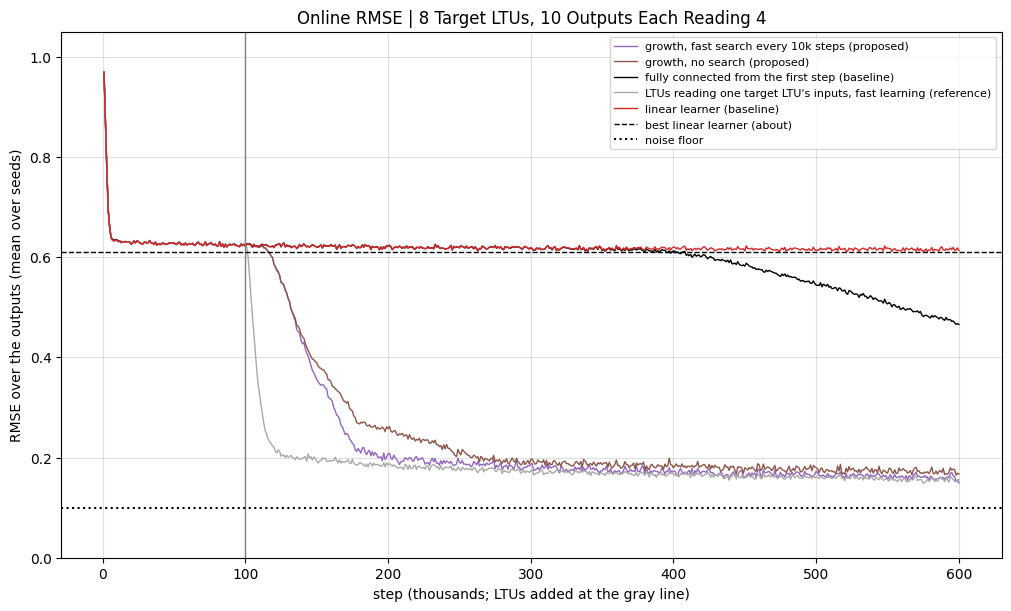

In [7]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {f'growth, fast search every {PERIOD // 1000}k steps (proposed)': (GROWTH, 'tab:purple'),
           'growth, no search (proposed)': (GROWTH_NO_SEARCH, 'tab:brown'),
           'fully connected from the first step (baseline)': (DENSE, 'black'),
           "LTUs reading one target LTU's inputs, fast learning (reference)": (REFERENCE, 'darkgray'),
           'linear learner (baseline)': (LINEAR, 'tab:red')}

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
for label, (config, color) in METHODS.items():
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner (about)')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE over the outputs (mean over seeds)',
       ylim=(0, 1.05), title=f'Online RMSE | {N_TARGETS} Target LTUs, {N_OUTPUTS} Outputs Each Reading {OUTPUT_FAN_IN}')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

5 seeds per configuration. The notebook takes about 1.5 minutes.

- **More outputs make the features easier to find**, as hypothesized: growth with search reaches RMSE 0.2 a median 85k
  steps after the LTUs are added, against 271k with one output (`05_fast_feature_search.ipynb`), and ends at 0.16
  (reference 0.156). It starts improving as soon as the LTUs are added, where with one output it stayed flat for about
  100k steps.
- **Without search it is a little slower**: 0.2 in 144k, final 0.17.
- **Fully connected gets past the linear learner, but late**: it starts improving around step 380k and ends at 0.49,
  still falling (with one output it stayed at 0.616).